# 2. Recover a time-varying PSD

## Goal
Estimate $S_A(t,f)$ from the nonstationary **channel-A time series** created
in [notebook 1](01_generate_data.ipynb). We use the library to form local
Fourier statistics, fit a tensor log-P-spline, and reconstruct the PSD.

This is an exploratory VI point reconstruction under a locally stationary
power likelihood. Windowing and finite-time effects remain approximations;
we do not use the VI draws as calibrated uncertainty intervals.

## Setup
Run notebook 1 once, then select **Restart Kernel and Run All Cells** here.
The fitting cells use public LogPSplinePSD functions.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from log_psplines import (
    PowerConfig,
    PowerData,
    TimeSeries,
    fit,
    local_wishart_grid,
    mask_power,
)

from lisa_case_studies.noise import XYZ_TO_AET
from lisa_case_studies.notebook_tools import COLORS, style
from lisa_case_studies.orbit_reference import DAY
from lisa_case_studies.tutorial_data import (
    MatrixSimulation,
    amplitude,
    load_data,
    workspace,
)

style()
a = load_data("scalar_a")

## Step 1 — Form local Fourier powers
Use non-overlapping Hann-tapered windows. Each window supplies complex
Fourier coefficients; for one channel, twice its squared magnitude is a
summed power with two real degrees of freedom under the local Whittle model.
The library normalizes these coefficients to one-sided PSD units.

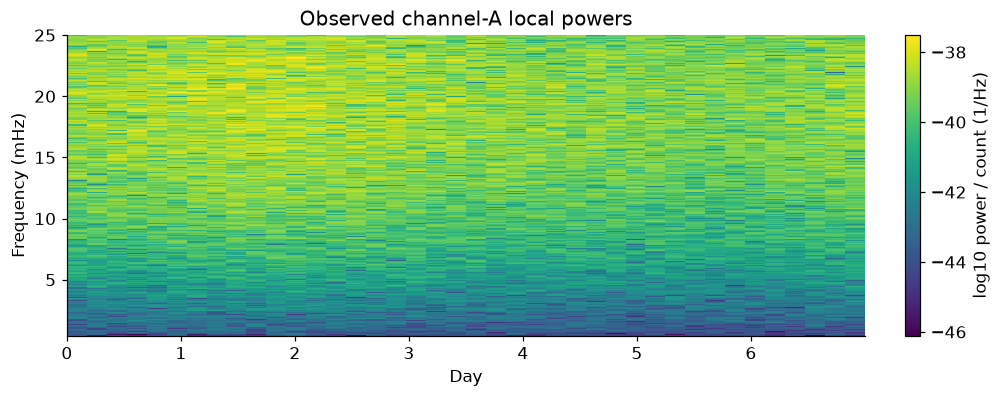

In [2]:
grid = local_wishart_grid(
    TimeSeries(a["data"], a["time"]), segment_length=3024, window="hann"
)
band = (grid.frequency >= 0.4e-3) & (grid.frequency <= 25e-3)
frequency = grid.frequency[band]
time_days = grid.time / DAY
powers = 2 * grid.Y[:, band, 0, 0].real
counts = 2 * grid.counts[:, band]
fig, ax = plt.subplots(layout="constrained")
mesh = ax.pcolormesh(
    time_days,
    frequency * 1000,
    np.log10(powers / counts).T,
    shading="auto",
    cmap="viridis",
)
ax.set(xlabel="Day", ylabel="Frequency (mHz)", title="Observed channel-A local powers")
fig.colorbar(mesh, ax=ax, label="log10 power / count (1/Hz)")
plt.show()

The powers are noisy observations, not the fitted PSD. A Hann window reduces
leakage but correlates nearby Fourier bins, so the power likelihood remains
an approximation.

## Step 2 — Fix the training/held-out split
Hold out every fourth time row. Numerical scaling uses training powers only.
Neither the injected spectrum nor held-out powers chooses knots or priors.

In [3]:
training = np.arange(len(time_days)) % 4 != 2
scale = float(np.median((powers / counts)[training]))
data = PowerData(
    powers / scale, counts, frequency, time_days, units="one-sided PSD / training scale"
)
training_data = mask_power(data, np.broadcast_to(training[:, None], powers.shape))
pd.DataFrame(
    {"Time rows": [training.sum(), (~training).sum()]}, index=["Training", "Held out"]
)

,Time rows
Training,30
Held out,10


## Step 3 — Call the library fitter
The tensor model learns $\log S_A(t,f)$. Frequency knots are logarithmically
spaced; the time basis is smooth across the week. All settings are fixed
before viewing reconstruction errors.

In [4]:
config = PowerConfig(
    method="vi",
    n_interior_knots_time=3,
    interior_knots_freq=np.geomspace(frequency[0], frequency[-1], 18)[1:-1],
    vi_steps=5000,
    vi_lr=0.03,
    vi_early_stopping=False,
    vi_posterior_draws=96,
    spectrum_draws=64,
    progress_bar=False,
    seed=7,
)
result = fit(training_data, config)
estimate = np.asarray(result.quantiles())[1, ..., 0, 0].real * scale

W1106 12:12:39.540363 2372656 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


## Step 4 — Compare the recovered PSD with the injected channel spectrum
Truth enters for the first time in this notebook at this evaluation step.
The reference below is the local evolutionary spectrum; a finite-window
expected periodogram can differ from it.

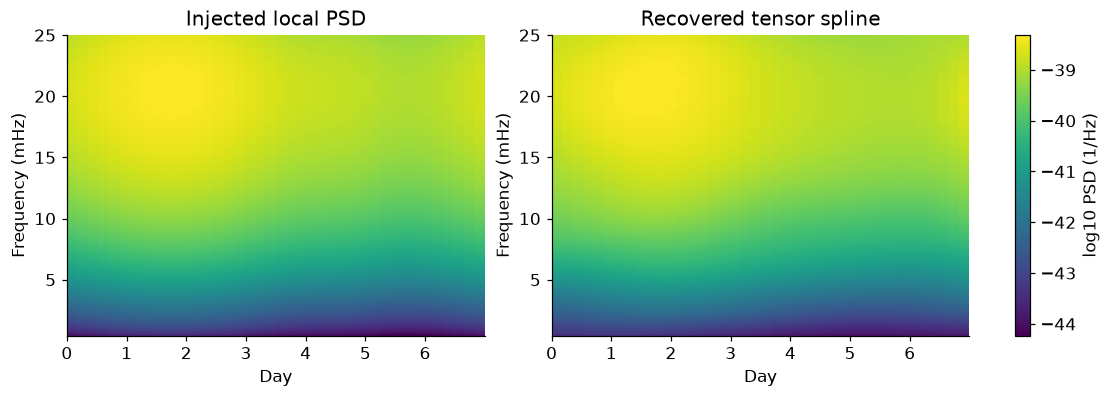

In [5]:
frozen = MatrixSimulation(
    len(a["time"]), float(a["dt"]), np.array([0.0]), a["light_times"][None]
)
a_vector = XYZ_TO_AET[0]
base_matrix = frozen.spectrum(np.array([0.0]), frequency)[0]
base_psd = np.einsum("i,fij,j->f", a_vector, base_matrix, a_vector).real
truth = amplitude(time_days * DAY, float(a["duration"]))[:, None] ** 2 * base_psd[None]
lo, hi = np.log10(truth).min(), np.log10(truth).max()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, values, title in zip(
    axes,
    (truth, estimate),
    ("Injected local PSD", "Recovered tensor spline"),
    strict=True,
):
    mesh = ax.pcolormesh(
        time_days,
        frequency * 1000,
        np.log10(values).T,
        shading="auto",
        cmap="viridis",
        vmin=lo,
        vmax=hi,
    )
    ax.set(xlabel="Day", ylabel="Frequency (mHz)", title=title)
fig.colorbar(mesh, ax=axes, label="log10 PSD (1/Hz)")
plt.show()

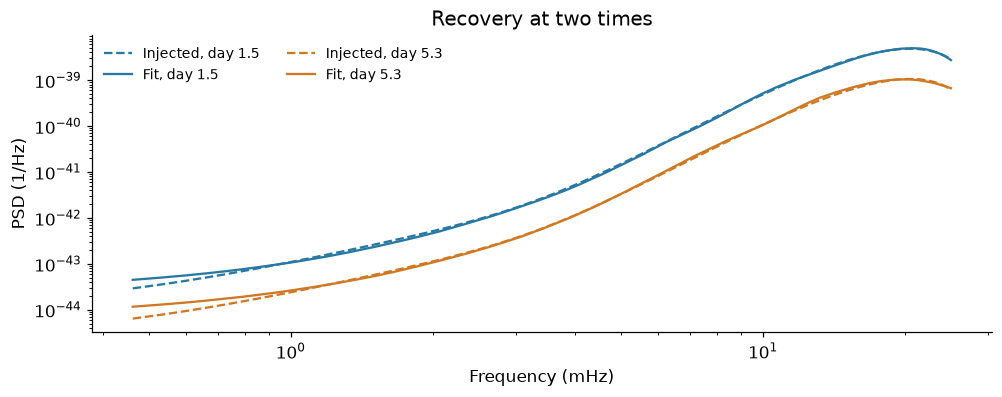

In [6]:
fig, ax = plt.subplots(layout="constrained")
for index, color in ((8, COLORS["X"]), (30, COLORS["Y"])):
    ax.loglog(
        frequency * 1000,
        truth[index],
        color=color,
        ls="--",
        label=f"Injected, day {time_days[index]:.1f}",
    )
    ax.loglog(
        frequency * 1000,
        estimate[index],
        color=color,
        label=f"Fit, day {time_days[index]:.1f}",
    )
ax.set(xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title="Recovery at two times")
ax.legend(ncol=2, fontsize=9, frameon=False)
plt.show()

## Checks
Report error on the fixed held-out rows, then inspect the optimization loss.
A stable ELBO is an optimization check, not a posterior-convergence guarantee.

In [7]:
heldout_rmse = float(
    np.sqrt(np.mean(np.log10(estimate[~training] / truth[~training]) ** 2))
)
assert np.isfinite(estimate).all() and np.all(estimate > 0)
assert np.isfinite(result.vi.losses).all()
pd.DataFrame(
    {
        "Held-out log10 RMSE": [heldout_rmse],
        "Held-out cells": [int((~training).sum() * len(frequency))],
    }
)

,Held-out log10 RMSE,Held-out cells
0,0.040789,3720


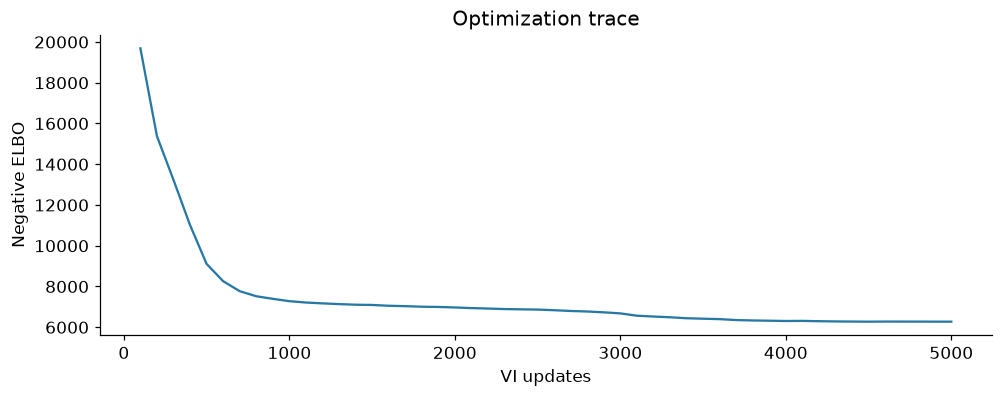

In [8]:
losses = np.asarray(result.vi.losses)
fig, ax = plt.subplots(layout="constrained")
ax.plot(np.linspace(100, config.vi_steps, len(losses)), losses, color=COLORS["X"])
ax.set(xlabel="VI updates", ylabel="Negative ELBO", title="Optimization trace")
plt.show()
np.savez_compressed(
    workspace() / "time_varying_recovery.npz",
    frequency=frequency,
    time_days=time_days,
    estimate=estimate,
    truth=truth,
    training=training,
    heldout_rmse=heldout_rmse,
    losses=losses,
    physical_scale=scale,
)

## Next steps
[Estimate the full stationary XYZ matrix](03_xyz_psd.ipynb). The main change
is to model complex cross-channel structure rather than a single PSD.